In [25]:
from pathlib import Path
import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import PoissonRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.exceptions import ConvergenceWarning
from sklearn.base import clone
from sklearn.model_selection import ParameterGrid
import warnings

ROOT = Path('/Users/huangzhihao/cis5450-bike-demand-forecasting')
DATA = ROOT / 'data/clean/station_hour_clean.parquet'
assert DATA.exists(), f'Missing data: {DATA}'
N_STATIONS = None
con = duckdb.connect()
con.execute("SET TIMEZONE = 'America/New_York'")
con.read_parquet(str(DATA)).create_view('panel')
con.sql('SELECT * FROM panel LIMIT 5').show()


┌────────────┬──────────────────────────┬─────────────────────┬────────────┬──────────┬───────────────┬────────────────────────┐
│ station_id │         hour_utc         │     hour_local      │ departures │ arrivals │ inferred_zero │ eligible_at_hour_start │
│  varchar   │ timestamp with time zone │      timestamp      │   int32    │  int32   │    boolean    │        boolean         │
├────────────┼──────────────────────────┼─────────────────────┼────────────┼──────────┼───────────────┼────────────────────────┤
│ 2832.03    │ 2025-01-01 00:00:00-05   │ 2025-01-01 00:00:00 │          0 │        1 │ false         │ false                  │
│ 2883.03    │ 2025-01-01 00:00:00-05   │ 2025-01-01 00:00:00 │          2 │        0 │ false         │ false                  │
│ 2898.01    │ 2025-01-01 00:00:00-05   │ 2025-01-01 00:00:00 │          0 │        2 │ false         │ false                  │
│ 2932.03    │ 2025-01-01 00:00:00-05   │ 2025-01-01 00:00:00 │          0 │        2 │ false    

In [24]:
# Select stations and construct strictly historical features
limit_sql = '' if N_STATIONS is None else f'LIMIT {int(N_STATIONS)}'
con.execute(f"""
CREATE OR REPLACE TEMP TABLE selected_stations AS
SELECT station_id
FROM panel
WHERE eligible_at_hour_start
  AND hour_local >= TIMESTAMP '2025-04-01'
  AND hour_local < TIMESTAMP '2025-08-01'
GROUP BY station_id
ORDER BY SUM(departures + arrivals) DESC, station_id
{limit_sql}
""")

con.execute("""
CREATE OR REPLACE TEMP TABLE history AS
SELECT p.* FROM panel p JOIN selected_stations USING (station_id)
WHERE hour_local >= TIMESTAMP '2025-03-01'
  AND hour_local < TIMESTAMP '2025-10-01'
""")
con.execute("""
CREATE OR REPLACE TEMP TABLE history_features AS
SELECT *,
 AVG(departures) OVER w AS dep_mean_24h,
 AVG(arrivals) OVER w AS arr_mean_24h,
 COUNT(*) OVER w AS history_rows_24h
FROM history
WINDOW w AS (
 PARTITION BY station_id ORDER BY hour_utc
 RANGE BETWEEN INTERVAL '24 hours' PRECEDING AND INTERVAL '1 hour' PRECEDING
)
""")
lag_select, lag_joins = [], []
for lag in [1, 24, 168]:
    alias = f'h{lag}'
    lag_select += [f'{alias}.departures AS dep_lag_{lag}',
                   f'{alias}.arrivals AS arr_lag_{lag}']
    lag_joins.append(f"LEFT JOIN history {alias} ON t.station_id={alias}.station_id "
                     f"AND {alias}.hour_utc=t.hour_utc-INTERVAL '{lag} hours'")

df = con.sql(f"""
SELECT t.station_id, t.hour_utc, t.hour_local,
       t.departures, t.arrivals,
       EXTRACT(hour FROM t.hour_local)::INTEGER AS hour,
       EXTRACT(isodow FROM t.hour_local)::INTEGER AS weekday,
       EXTRACT(month FROM t.hour_local)::INTEGER AS month,
       (EXTRACT(isodow FROM t.hour_local) >= 6)::INTEGER AS weekend,
       t.dep_mean_24h, t.arr_mean_24h, t.history_rows_24h,
       {', '.join(lag_select)}
FROM history_features t
{' '.join(lag_joins)}
WHERE t.eligible_at_hour_start
  AND t.hour_local >= TIMESTAMP '2025-04-01'
ORDER BY t.hour_utc, t.station_id
""").df()

train = df.loc[
    (df.hour_local >= "2025-04-01") &
    (df.hour_local < "2025-08-01")
].copy()

valid = df.loc[
    (df.hour_local >= "2025-08-01") &
    (df.hour_local < "2025-09-01")
].copy()

test = df.loc[
    (df.hour_local >= "2025-09-01") &
    (df.hour_local < "2025-10-01")
].copy()

assert not train.empty and not valid.empty and not test.empty
assert train.hour_utc.max() < valid.hour_utc.min()
assert valid.hour_utc.max() < test.hour_utc.min()
assert not df.duplicated(["station_id", "hour_utc"]).any()

print("Stations:", df.station_id.nunique())
print("Training rows:", len(train))
print("Validation rows:", len(valid))
print("Test rows:", len(test))

Stations: 2342
Training rows: 6396447
Validation rows: 1601673
Test rows: 1548059


In [30]:
# Refresh historical average baseline using current train and valid
targets = ['departures', 'arrivals']

means = train.groupby(['station_id', 'hour'])[targets].mean()
station_means = train.groupby('station_id')[targets].mean()
keys = pd.MultiIndex.from_frame(valid[['station_id', 'hour']])

for target in targets:
    p = pd.Series(
        means[target].reindex(keys).to_numpy(),
        index=valid.index,
    )
    p = p.fillna(valid['station_id'].map(station_means[target]))
    p = p.fillna(train[target].mean())

    predictions[('Historical average', target)] = p.to_numpy()

    assert len(p) == len(valid) and np.isfinite(p).all()
    print(target, "baseline updated:", len(p))


departures baseline updated: 1601673
arrivals baseline updated: 1601673


In [26]:
# Regression models
categorical = ['station_id', 'hour', 'weekday', 'weekend']
numerical = ['dep_lag_1', 'arr_lag_1', 'dep_lag_24', 'arr_lag_24',
             'dep_lag_168', 'arr_lag_168', 'dep_mean_24h', 'arr_mean_24h',
             'history_rows_24h']
features = categorical + numerical

def preprocessing(scale):
    steps = [('imputer', SimpleImputer(strategy='median', add_indicator=True))]
    if scale:
        steps.append(('scale', StandardScaler()))
    return ColumnTransformer([
        ('categories', OneHotEncoder(handle_unknown='ignore'), categorical),
        ('numbers', Pipeline(steps), numerical),
    ])

def poisson_preprocessing():
    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(
            strategy="median",
            add_indicator=True
        )),
        ("log1p", FunctionTransformer(
            np.log1p,
            feature_names_out="one-to-one"
        )),
        ("scale", StandardScaler()),
    ])

    return ColumnTransformer([
        ("categories", OneHotEncoder(
            handle_unknown="ignore"
        ), categorical),
        ("numbers", numeric_pipeline, numerical),
    ])

model_specs = {
    "Poisson": (
        PoissonRegressor(max_iter=2000),
        {"alpha": [0.01, 0.1, 1.0, 10.0]},
    ),
    "Random forest": (
        RandomForestRegressor(
            n_estimators=100,
            min_samples_leaf=10,
            n_jobs=4,
            random_state=42,
        ),
        {"max_depth": [12, 16, 20]},
    ),
    "Gradient boosting": (
        GradientBoostingRegressor(
            n_estimators=100,
            min_samples_leaf=10,
            subsample=0.8,
            random_state=42,
        ),
        {
            "max_depth": [2, 3],
            "learning_rate": [0.05, 0.1],
        },
    ),
}

models = {}
best_params = {}
tuning_rows = []
predictions = {
    key: value
    for key, value in predictions.items()
    if key[0] == "Historical average"
}

for target in targets:
    for name, (estimator, grid) in model_specs.items():
        best_mae = np.inf

        for params in ParameterGrid(grid):
            print("Tuning:", name, target, params, flush=True)

            prep = (
                poisson_preprocessing()
                if name == "Poisson"
                else preprocessing(False)
            )

            model = Pipeline([
                ("preprocess", prep),
                ("model", clone(estimator).set_params(**params)),
            ])

            with warnings.catch_warnings(record=True) as caught:
                warnings.simplefilter("always", ConvergenceWarning)
                model.fit(train[features], train[target])

            converged = not any(
                issubclass(w.category, ConvergenceWarning)
                for w in caught
            )

            p = model.predict(valid[features])
            assert np.isfinite(p).all()
            p = np.maximum(p, 0)

            mae = mean_absolute_error(valid[target], p)
            rmse = np.sqrt(mean_squared_error(valid[target], p))

            tuning_rows.append({
                "model": name,
                "target": target,
                "params": params.copy(),
                "converged": converged,
                "MAE": mae,
                "RMSE": rmse,
                "prediction_max": p.max(),
            })
            
            if converged and mae < best_mae:
                best_mae = mae
                best_params[(name, target)] = params.copy()
                models[(name, target)] = model
                predictions[(name, target)] = p

        if (name, target) not in models:
            raise RuntimeError(
                f"No converged candidate: {name}, {target}"
            )
            
tuning_results = pd.DataFrame(tuning_rows)
display(tuning_results.sort_values(["target", "model", "MAE"]))

Tuning: Poisson departures {'alpha': 0.01}
Tuning: Poisson departures {'alpha': 0.1}
Tuning: Poisson departures {'alpha': 1.0}
Tuning: Poisson departures {'alpha': 10.0}
Tuning: Random forest departures {'max_depth': 12}
Tuning: Random forest departures {'max_depth': 16}
Tuning: Random forest departures {'max_depth': 20}
Tuning: Gradient boosting departures {'learning_rate': 0.05, 'max_depth': 2}
Tuning: Gradient boosting departures {'learning_rate': 0.05, 'max_depth': 3}
Tuning: Gradient boosting departures {'learning_rate': 0.1, 'max_depth': 2}
Tuning: Gradient boosting departures {'learning_rate': 0.1, 'max_depth': 3}
Tuning: Poisson arrivals {'alpha': 0.01}
Tuning: Poisson arrivals {'alpha': 0.1}
Tuning: Poisson arrivals {'alpha': 1.0}
Tuning: Poisson arrivals {'alpha': 10.0}
Tuning: Random forest arrivals {'max_depth': 12}
Tuning: Random forest arrivals {'max_depth': 16}
Tuning: Random forest arrivals {'max_depth': 20}
Tuning: Gradient boosting arrivals {'learning_rate': 0.05, 'ma

,model,target,params,converged,MAE,RMSE,prediction_max
21,Gradient boosting,arrivals,"{'learning_rate': 0.1, 'max_depth': 3}",True,1.474767,2.678571,98.270766
19,Gradient boosting,arrivals,"{'learning_rate': 0.05, 'max_depth': 3}",True,1.501675,2.743006,82.502815
20,Gradient boosting,arrivals,"{'learning_rate': 0.1, 'max_depth': 2}",True,1.508777,2.752184,89.164938
18,Gradient boosting,arrivals,"{'learning_rate': 0.05, 'max_depth': 2}",True,1.537791,2.820495,64.670314
11,Poisson,arrivals,{'alpha': 0.01},True,1.542725,2.871070,215.576715
12,Poisson,arrivals,{'alpha': 0.1},True,1.584070,2.963958,224.925842
13,Poisson,arrivals,{'alpha': 1.0},True,1.620342,3.013495,175.658347
14,Poisson,arrivals,{'alpha': 10.0},True,1.870238,3.482244,65.878766
17,Random forest,arrivals,{'max_depth': 20},True,1.412518,2.575654,108.421451
16,Random forest,arrivals,{'max_depth': 16},True,1.423987,2.587250,108.421451


,model,target,period,n,MAE,RMSE
12,Random forest,arrivals,All hours,1601673,1.412518,2.575654
14,Gradient boosting,arrivals,All hours,1601673,1.474767,2.678571
10,Poisson,arrivals,All hours,1601673,1.542725,2.871070
2,Historical average,arrivals,All hours,1601673,1.592596,3.370129
13,Random forest,arrivals,Peak hours,271664,1.903234,3.253491
15,Gradient boosting,arrivals,Peak hours,271664,1.993674,3.428920
11,Poisson,arrivals,Peak hours,271664,2.109860,3.749324
3,Historical average,arrivals,Peak hours,271664,2.146807,4.064702
6,Random forest,departures,All hours,1601673,1.391761,2.560847
8,Gradient boosting,departures,All hours,1601673,1.468101,2.685680


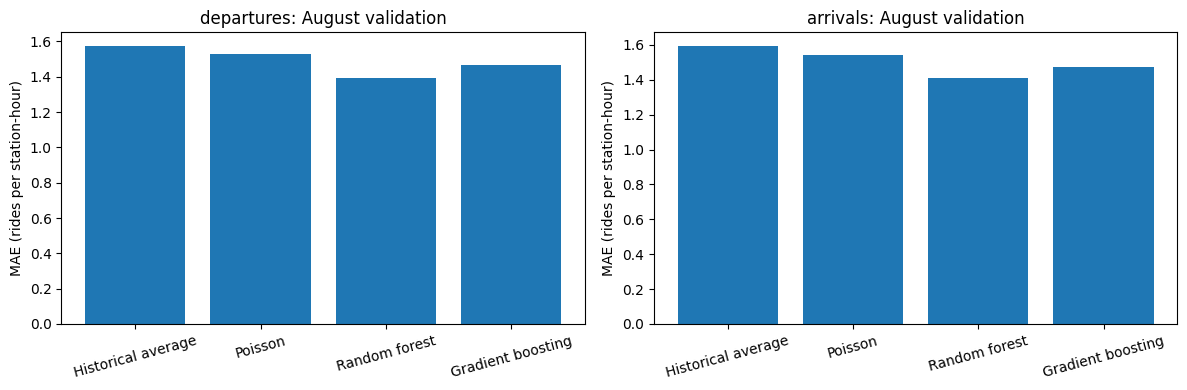

Methods selected using August: {'departures': 'Random forest', 'arrivals': 'Random forest'}


In [31]:
# August validation results
peak = ((valid.weekday <= 5) & valid.hour.isin([7, 8, 9, 16, 17, 18])).to_numpy()
rows = []
for (name, target), p in predictions.items():
    y = valid[target].to_numpy()
    assert len(p) == len(y) and np.isfinite(p).all()
    for label, mask in [('All hours', np.ones(len(y), dtype=bool)), ('Peak hours', peak)]:
        rows.append({
            'model': name, 'target': target, 'period': label, 'n': int(mask.sum()),
            'MAE': mean_absolute_error(y[mask], p[mask]),
            'RMSE': np.sqrt(mean_squared_error(y[mask], p[mask])),
        })
results = pd.DataFrame(rows)
display(results.sort_values(['target', 'period', 'MAE']))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, target in zip(axes, targets):
    r = results[(results.target == target) & (results.period == 'All hours')]
    ax.bar(r.model, r.MAE)
    ax.set_title(f'{target}: August validation')
    ax.set_ylabel('MAE (rides per station-hour)')
    ax.tick_params(axis='x', rotation=15)
plt.tight_layout()
plt.show()
winner_rows = (
    results.loc[results.period == "All hours"]
    .sort_values(["MAE", "model"])
    .drop_duplicates("target")
)

selected_methods = dict(zip(
    winner_rows.target,
    winner_rows.model,
))

print("Methods selected using August:", selected_methods)


Final training: Poisson — departures
Completed: Poisson — departures
Final training: Random forest — departures
Completed: Random forest — departures
Final training: Gradient boosting — departures
Completed: Gradient boosting — departures
Final training: Poisson — arrivals
Completed: Poisson — arrivals
Final training: Random forest — arrivals
Completed: Random forest — arrivals
Final training: Gradient boosting — arrivals
Completed: Gradient boosting — arrivals


,model,target,period,n,MAE,RMSE,selected_on_August
14,Gradient boosting,arrivals,All hours,1548059,1.528577,2.808121,False
2,Historical average,arrivals,All hours,1548059,1.700829,3.513229,False
10,Poisson,arrivals,All hours,1548059,1.603799,3.047424,False
12,Random forest,arrivals,All hours,1548059,1.453765,2.676403,True
15,Gradient boosting,arrivals,Peak hours,284323,2.272671,4.144200,False
3,Historical average,arrivals,Peak hours,284323,2.705151,5.376120,False
11,Poisson,arrivals,Peak hours,284323,2.383431,4.484178,False
13,Random forest,arrivals,Peak hours,284323,2.146745,3.901003,True
8,Gradient boosting,departures,All hours,1548059,1.508057,2.767033,False
0,Historical average,departures,All hours,1548059,1.680296,3.459090,False


departures: August-selected model = Random forest; test MAE = 1.428; MAE reduction vs baseline = 14.99%
arrivals: August-selected model = Random forest; test MAE = 1.454; MAE reduction vs baseline = 14.53%


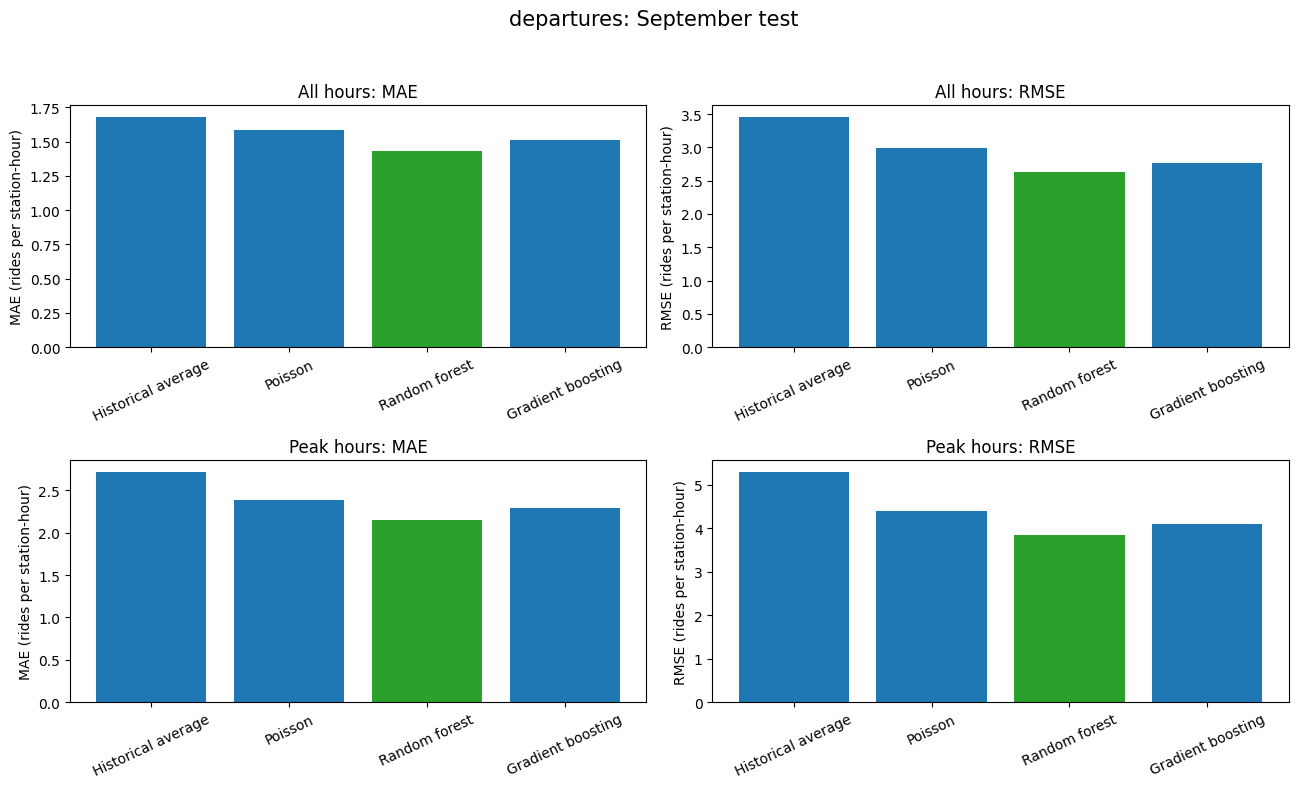

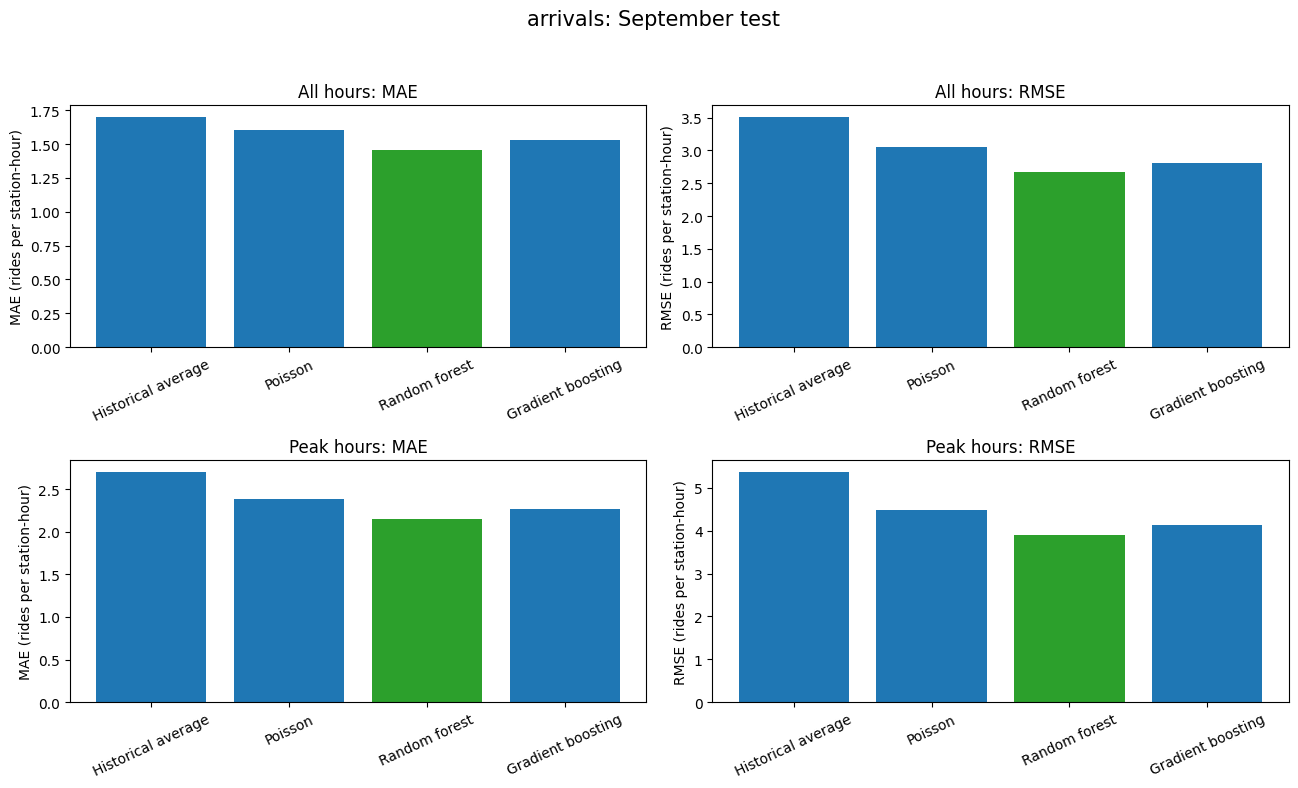

Tables and figures saved to: /Users/huangzhihao/cis5450-bike-demand-forecasting/notebooks/results


In [32]:
# Final training and testing
from pathlib import Path

development = pd.concat([train, valid], ignore_index=True)

assert development.hour_utc.max() < test.hour_utc.min()
assert all(target in selected_methods for target in targets)

final_models = {}
test_predictions = {}

# Historical average: fit on train + validation
hourly_means = development.groupby(
    ["station_id", "hour"]
)[targets].mean()

station_means = development.groupby("station_id")[targets].mean()
test_keys = pd.MultiIndex.from_frame(test[["station_id", "hour"]])

for target in targets:
    p = pd.Series(
        hourly_means[target].reindex(test_keys).to_numpy(),
        index=test.index,
    )
    p = p.fillna(test["station_id"].map(station_means[target]))
    p = p.fillna(development[target].mean())

    p = p.to_numpy()
    assert len(p) == len(test) and np.isfinite(p).all()

    test_predictions[("Historical average", target)] = p


# Refit each model with its August-selected hyperparameters
for (name, target), validation_model in models.items():
    print(f"Final training: {name} — {target}", flush=True)

    final_model = clone(validation_model)

    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always", ConvergenceWarning)

        final_model.fit(
            development[features],
            development[target],
        )

    if any(
        issubclass(w.category, ConvergenceWarning)
        for w in caught
    ):
        raise RuntimeError(
            f"Final model did not converge: {name}, {target}"
        )

    p = final_model.predict(test[features])

    assert len(p) == len(test)
    assert np.isfinite(p).all()

    final_models[(name, target)] = final_model
    test_predictions[(name, target)] = np.maximum(p, 0)

    print(f"Completed: {name} — {target}", flush=True)

test_peak = (
    (test["weekday"] <= 5)
    & test["hour"].isin([7, 8, 9, 16, 17, 18])
).to_numpy()

test_rows = []

for (name, target), p in test_predictions.items():
    y = test[target].to_numpy()

    assert len(p) == len(y) and np.isfinite(p).all()

    for period, mask in [
        ("All hours", np.ones(len(test), dtype=bool)),
        ("Peak hours", test_peak),
    ]:
        if not mask.any():
            continue

        test_rows.append({
            "model": name,
            "target": target,
            "period": period,
            "n": int(mask.sum()),
            "MAE": mean_absolute_error(y[mask], p[mask]),
            "RMSE": np.sqrt(
                mean_squared_error(y[mask], p[mask])
            ),
            "selected_on_August": (
                selected_methods[target] == name
            ),
        })

test_results = pd.DataFrame(test_rows)

display(
    test_results.sort_values(["target", "period", "model"])
)

overall = test_results[
    test_results["period"] == "All hours"
]

for target in targets:
    scores = overall[
        overall["target"] == target
    ].set_index("model")

    selected_name = selected_methods[target]
    baseline_mae = scores.loc["Historical average", "MAE"]
    selected_mae = scores.loc[selected_name, "MAE"]

    improvement = (
        100 * (baseline_mae - selected_mae) / baseline_mae
        if baseline_mae > 0
        else np.nan
    )

    print(
        f"{target}: August-selected model = {selected_name}; "
        f"test MAE = {selected_mae:.3f}; "
        f"MAE reduction vs baseline = {improvement:.2f}%"
    )


out = Path("results")
out.mkdir(exist_ok=True)

results.to_csv(
    out / "august_validation_results.csv",
    index=False,
)
test_results.to_csv(
    out / "september_test_results.csv",
    index=False,
)
tuning_results.to_csv(
    out / "tuning_results.csv",
    index=False,
)

model_order = [
    "Historical average",
    "Poisson",
    "Random forest",
    "Gradient boosting",
]

for target in targets:
    fig, axes = plt.subplots(2, 2, figsize=(13, 8))

    for row, period in enumerate(["All hours", "Peak hours"]):
        r = (
            test_results[
                (test_results["target"] == target)
                & (test_results["period"] == period)
            ]
            .set_index("model")
            .reindex(model_order)
        )

        for col, metric in enumerate(["MAE", "RMSE"]):
            ax = axes[row, col]

            colors = [
                "tab:green"
                if name == selected_methods[target]
                else "tab:blue"
                for name in model_order
            ]

            ax.bar(model_order, r[metric], color=colors)
            ax.set_title(f"{period}: {metric}")
            ax.set_ylabel(f"{metric} (rides per station-hour)")
            ax.tick_params(axis="x", rotation=25)

    fig.suptitle(f"{target}: September test", fontsize=15)
    fig.tight_layout(rect=[0, 0, 1, 0.95])

    fig.savefig(
        out / f"september_test_{target}.png",
        dpi=200,
        bbox_inches="tight",
    )
    plt.show()

print(f"Tables and figures saved to: {out.resolve()}")

In [33]:
import joblib

joblib.dump(
    {
        "final_models": final_models,
        "test_predictions": test_predictions,
        "selected_methods": selected_methods,
        "best_params": best_params,
    },
    out / "final_models_and_predictions.joblib",
)

['results/final_models_and_predictions.joblib']